# Hist2ST: single-patch prediction

EffNet-5 trained without a teacher, using the fold-5 checkpoint. The included patch is from held-out patient `23287` (slide `23287_C1`, patch 0).

Run all cells. Pearson and Spearman are computed **across the 845 genes of this patch**. They are patch-wise (the code's cell-wise convention), not gene-wise correlations across many patches or the mean of fold 5.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import warnings
warnings.filterwarnings("ignore", message="IProgress not found.*")

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torchvision import transforms
from scipy.stats import pearsonr, spearmanr
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "code_model_training/models/model_eff_net_versions.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the TinyHistModels folder.")
sys.path.insert(0, str(ROOT / "code_model_training/models"))
from model_eff_net_versions import EfficientNetTinyStudent

DEMO = ROOT / "demo"
metadata = json.loads((DEMO / "sample/metadata.json").read_text())

# Edit these paths to use another patch and its matching raw counts.
PATCH_PATH = DEMO / "sample/patch.png"
TARGET_PATH = DEMO / "sample/expression.csv"  # Use None for prediction only.
CHECKPOINT = DEMO / metadata["checkpoint"]

torch.set_num_threads(4)
device = torch.device("cpu")  # This model also supports CUDA.


## Input preview (optional)
For another patch, change `PATCH_PATH` and `TARGET_PATH` in the setup cell above. Targets must be matching raw gene counts (`gene,count`). Set `TARGET_PATH = None` for prediction only. The model cell loads the patch directly, so this preview can be skipped.

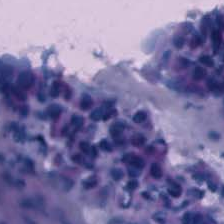

Patch size: (224, 224)


In [2]:
with Image.open(PATCH_PATH) as image:
    patch = image.convert("RGB")
display(patch)
print(f"Patch size: {patch.size}")


In [3]:
genes = np.load(ROOT / "code_model_training/gene_outputs/hist2st_845.npy",
                allow_pickle=True).astype(str)
assert len(genes) == metadata["num_genes"] == 845
assert hashlib.sha256(CHECKPOINT.read_bytes()).hexdigest() == metadata["checkpoint_sha256"]

model = EfficientNetTinyStudent(num_genes=len(genes), phi=metadata["phi"])
state = torch.load(CHECKPOINT, map_location="cpu", weights_only=True)
model.load_state_dict(state, strict=True)
model = model.to(device).eval()
print(f"EffNet-5 | fold 5 | {sum(p.numel() for p in model.parameters()):,} parameters")

if PATCH_PATH.resolve() != (DEMO / "sample/patch.png").resolve() and TARGET_PATH == DEMO / "sample/expression.csv":
    raise ValueError("Provide targets for the new patch, or set TARGET_PATH = None.")
with Image.open(PATCH_PATH) as image:
    patch = image.convert("RGB")

# Same image preprocessing as this training run; no ImageNet normalization.
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])
with torch.inference_mode():
    prediction = model(transform(patch).unsqueeze(0).to(device))[0].cpu().numpy()
assert prediction.shape == (len(genes),) and np.isfinite(prediction).all()


EffNet-5 | fold 5 | 300,552 parameters


## Prediction and metrics
Targets use the training normalization: `log1p(count / (sum of panel counts + 1e-8) * 1e6)`. Predictions are not clipped. MAPE excludes targets with absolute value ≤ `1e-3`, matching the original metric code. MAE and MSE are in log-normalized expression units.

In [4]:
result = pd.DataFrame({"gene": genes, "prediction": prediction})
if TARGET_PATH is not None:
    expression = pd.read_csv(TARGET_PATH)
    if not {"gene", "count"}.issubset(expression.columns):
        raise ValueError("Target CSV must contain gene and count columns.")
    if expression["gene"].duplicated().any():
        raise ValueError("Target gene names must be unique.")
    expression = expression.set_index("gene")
    missing = set(genes) - set(expression.index)
    if missing:
        raise ValueError(f"Missing {len(missing)} target genes.")
    counts = expression.loc[genes, "count"].to_numpy(dtype=np.float32)
    if not np.isfinite(counts).all() or np.any(counts < 0):
        raise ValueError("Expected finite, nonnegative raw counts.")
    target = np.log1p(counts / (counts.sum() + np.float32(1e-8)) * metadata["scale_factor"])
    result["target"] = target
    error = prediction - target
    nonzero = np.abs(target) > 1e-3
    varying = np.ptp(prediction) > 0 and np.ptp(target) > 0
    metrics = pd.Series({
        "Pearson (patch-wise)": float(pearsonr(target, prediction).statistic) if varying else np.nan,
        "Spearman (patch-wise)": float(spearmanr(target, prediction).statistic) if varying else np.nan,
        "MAE": float(np.mean(np.abs(error))),
        "MSE": float(np.mean(error ** 2)),
        "MAPE (%)": float(np.mean(np.abs(error[nonzero] / target[nonzero])) * 100) if nonzero.any() else np.nan,
    }, name="value")
    print(metrics.to_string(float_format=lambda value: f"{value:.6f}"))
    print(f"Genes: {len(genes)} | MAPE genes: {nonzero.sum()}")
else:
    print("Prediction only: no matching ground truth provided.")
display(result.head(10))


Pearson (patch-wise)     0.575767
Spearman (patch-wise)    0.525691
MAE                      2.057972
MSE                      8.491505
MAPE (%)                57.464046
Genes: 845 | MAPE genes: 245


,gene,prediction,target
0,ENSG00000004838,0.444083,0.000000
1,ENSG00000005020,0.236831,0.000000
2,ENSG00000005243,0.581447,0.000000
3,ENSG00000006016,0.164739,0.000000
4,ENSG00000006210,0.515913,0.000000
5,ENSG00000006712,0.754879,0.000000
6,ENSG00000007264,-0.010758,0.000000
7,ENSG00000007312,0.103511,0.000000
8,ENSG00000008394,3.065685,7.414196
9,ENSG00000008517,0.350137,0.000000


The checkpoint and sample details are in [`sample/metadata.json`](sample/metadata.json). This is a single-patch demo; full-dataset evaluation and significance analysis are not included.